# Twizzle: Model Comparison and Late Fusion (Person 2)

Run this after **both** model notebooks have finished (`DEV_MODE = False`). It reads only the files they exported
(`export/*/deployment_meta.json`, `predictions/*.npz`), so it needs no GPU.

It answers three questions for the report:
1. Which model is more accurate, especially on the six jump classes?
2. What does the accuracy cost in parameters, file size and CPU time? (the best research model is not automatically the best deployed model)
3. Does averaging the two models (late fusion) help enough to justify running both?

The test split is evaluated **once** (`EVALUATE_TEST`).

In [15]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path(os.environ.get("TWIZZLE_ROOT", Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()))
sys.path.insert(0, str(REPO_ROOT))
import twizzle_train as T

EVALUATE_TEST = True
SUFFIX = os.environ.get("TWIZZLE_SUFFIX", "")      # "_dev" to look at the DEV_MODE outputs
NAMES = ["x3d", "r2plus1d"]
LABEL = {"x3d": "X3D-S", "r2plus1d": "R(2+1)D-18"}

meta = {}
for n in NAMES:
    p = REPO_ROOT / ("export" + SUFFIX) / n / "deployment_meta.json"
    assert p.is_file(), f"{p} not found: finish that model's notebook first"
    meta[n] = json.loads(p.read_text())
    if meta[n].get("dev_mode"):
        print(f"[warn] {n} was exported from DEV_MODE: these are pipeline checks, not results")
print("loaded:", list(meta))

loaded: ['x3d', 'r2plus1d']


## 1. Cost and validation accuracy

,val_macro_F1,val_jump_macro_F1,params_M,onnx_MB,cpu_ms_median_2threads,train_min
model,,,,,,
X3D-S,0.886,0.832,3.00,12.0,145,29.6
R(2+1)D-18,0.908,0.861,31.31,125.2,1387,183.5


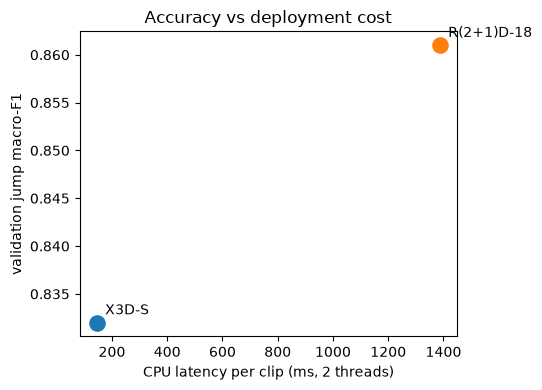

In [12]:
rows = []
for n, mt in meta.items():
    rows.append({"model": LABEL[n], "val_macro_F1": mt["val_macro_f1"], "val_jump_macro_F1": mt["val_jump_macro_f1"],
                 "params_M": round(mt.get("params_total", 0) / 1e6, 2), "onnx_MB": mt.get("onnx_mb"),
                 "cpu_ms_median_2threads": round(mt.get("cpu_ms_median", float("nan"))), "train_min": round(mt.get("train_seconds", 0) / 60, 1)})
cost = pd.DataFrame(rows).set_index("model").round(3)
display(cost)

fig, ax = plt.subplots(figsize=(5.5, 4))
for model, r in cost.iterrows():
    ax.scatter(r.cpu_ms_median_2threads, r.val_jump_macro_F1, s=120)
    ax.annotate(model, (r.cpu_ms_median_2threads, r.val_jump_macro_F1), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("CPU latency per clip (ms, 2 threads)"); ax.set_ylabel("validation jump macro-F1")
ax.set_title("Accuracy vs deployment cost"); plt.tight_layout(); plt.show()

## 2. Late fusion (tuned on validation only)

Fusion = a weighted average of the two models' calibrated probabilities. `w` is the weight of the first model. We choose `w` on validation and never on test. The two models must have seen exactly the same clips in the same order, which is asserted.

In [16]:
PRED = REPO_ROOT / ("predictions" + SUFFIX)
val = {n: T.load_predictions(PRED / f"{n}_val.npz") for n in NAMES}
a, b = NAMES
assert (val[a]["clip_ids"] == val[b]["clip_ids"]).all() and (val[a]["labels"] == val[b]["labels"]).all(), "models were evaluated on different clips/orders"

w, fusion_table = T.tune_fusion_weight(val[a]["probs_calibrated"], val[b]["probs_calibrated"], val[a]["labels"])
display(fusion_table.round(3))
fused_val = T.compute_metrics(val[a]["labels"], T.fuse_probs(val[a]["probs_calibrated"], val[b]["probs_calibrated"], w).argmax(1))
single = {n: T.compute_metrics(val[n]["labels"], val[n]["probs_calibrated"].argmax(1)) for n in NAMES}
print(f"chosen w ({LABEL[a]}) = {w}")
display(pd.DataFrame({LABEL[a]: single[a], LABEL[b]: single[b], "fused": fused_val}).drop(index="per_class_f1").T.round(3))

,w_model_A,macro_f1,jump_macro_f1,acc
0,0.0,0.908,0.861,0.947
1,0.1,0.909,0.863,0.948
2,0.2,0.912,0.869,0.950
3,0.3,0.917,0.878,0.953
4,0.4,0.921,0.885,0.955
5,0.5,0.924,0.892,0.958
6,0.6,0.910,0.868,0.951
7,0.7,0.902,0.855,0.946
8,0.8,0.896,0.846,0.943
9,0.9,0.889,0.836,0.939


chosen w (X3D-S) = 0.5


,acc,macro_f1,jump_macro_f1
X3D-S,0.937333,0.885729,0.831688
R(2+1)D-18,0.947333,0.907686,0.860568
fused,0.957667,0.923707,0.891572


## 3. Test split (once)

Only after the decision about which model(s) to deploy has been made. The fusion weight comes from validation.

,acc,macro_f1,jump_macro_f1
X3D-S,0.929,0.870,0.817
R(2+1)D-18,0.946,0.903,0.861
fused,0.952,0.911,0.878


,X3D-S,R(2+1)D-18,fused
Toeloop,0.897,0.911,0.918
Salchow,0.787,0.814,0.817
Flip,0.720,0.770,0.796
Loop,0.800,0.874,0.896
Lutz,0.776,0.828,0.854
Axel,0.926,0.966,0.984
CamelSpin,0.982,0.989,0.992
SitSpin,0.970,0.979,0.980
UprightSpin,0.946,0.955,0.956
NoBasic,0.771,0.848,0.836


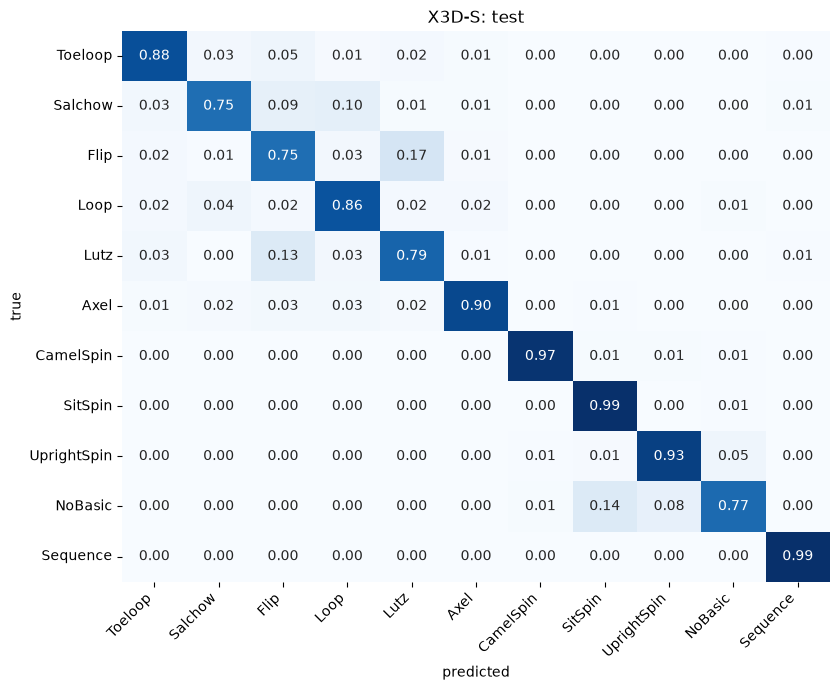

X3D-S top confusions: [('Flip', 'Lutz', 24), ('Lutz', 'Flip', 19), ('UprightSpin', 'NoBasic', 16), ('NoBasic', 'SitSpin', 13)]


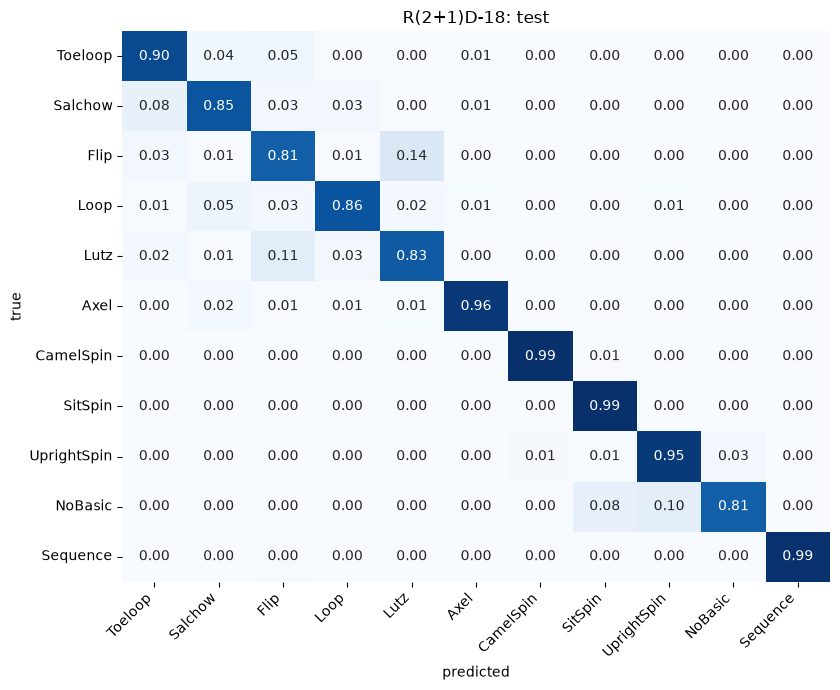

R(2+1)D-18 top confusions: [('Flip', 'Lutz', 20), ('Lutz', 'Flip', 16), ('Toeloop', 'Flip', 12), ('NoBasic', 'UprightSpin', 10)]


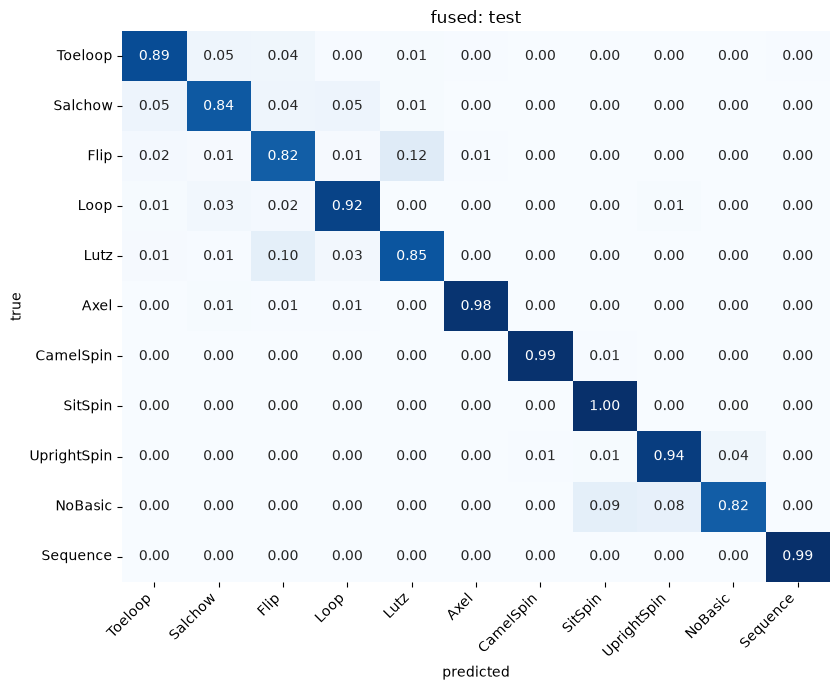

fused top confusions: [('Flip', 'Lutz', 17), ('Lutz', 'Flip', 14), ('UprightSpin', 'NoBasic', 13), ('Toeloop', 'Salchow', 11)]


In [17]:
if EVALUATE_TEST:
    test = {n: T.load_predictions(PRED / f"{n}_test.npz") for n in NAMES}
    assert (test[a]["clip_ids"] == test[b]["clip_ids"]).all()
    y = test[a]["labels"]
    fused_p = T.fuse_probs(test[a]["probs_calibrated"], test[b]["probs_calibrated"], w)
    res = {LABEL[n]: T.compute_metrics(y, test[n]["probs_calibrated"].argmax(1)) for n in NAMES}
    res["fused"] = T.compute_metrics(y, fused_p.argmax(1))
    summary = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "per_class_f1"} for k, v in res.items()}).T.round(3)
    display(summary)
    display(pd.DataFrame({k: np.round(v["per_class_f1"], 3) for k, v in res.items()}, index=T.CLASS_NAMES))

    from sklearn.metrics import confusion_matrix
    for name, probs in [(LABEL[a], test[a]["probs_calibrated"]), (LABEL[b], test[b]["probs_calibrated"]), ("fused", fused_p)]:
        cm = confusion_matrix(y, probs.argmax(1), labels=list(range(T.NUM_CLASSES)))
        T.plot_confusion(cm, f"{name}: test"); print(name, "top confusions:", T.top_confusions(cm, 4))
    summary.to_csv(REPO_ROOT / ("model_comparison" + SUFFIX + ".csv"))
else:
    print("EVALUATE_TEST is False: test split not touched.")

## 4. Decision for the report

Fill this in yourself from the tables above (do not let an AI write the conclusion for you):

* Which model is better on **jump macro-F1**, and by how much? Is the gap larger than the noise you would expect from the number of validation clips per class?
* What does the better model cost (CPU ms, MB, parameters)? Which model do we deploy, and why?
* Did fusion help? If the gain is small, is it worth running two models on 2 CPU cores?
* Which classes are confused by *both* models? (Those are limits of the data or of RGB-only input, not of one architecture.)